## Dawn Andrei Pamesa and Alba
## TS31

In [1]:
import pandas as pd
import matplotlib.pyplot as plt


df = pd.read_csv("heart_v2.csv")

print(df.head())
print(df.info())
print(df.isnull().sum())

   age  sex   BP  cholestrol  heart disease
0   70    1  130         322              1
1   67    0  115         564              0
2   57    1  124         261              1
3   64    1  128         263              0
4   74    0  120         269              0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 270 entries, 0 to 269
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   age            270 non-null    int64
 1   sex            270 non-null    int64
 2   BP             270 non-null    int64
 3   cholestrol     270 non-null    int64
 4   heart disease  270 non-null    int64
dtypes: int64(5)
memory usage: 10.7 KB
None
age              0
sex              0
BP               0
cholestrol       0
heart disease    0
dtype: int64


In [2]:
y = df["heart disease"]
X = df[["age", "sex", "BP", "cholestrol"]]

heart disease
0    150
1    120
Name: count, dtype: int64
heart disease
0    55.555556
1    44.444444
Name: count, dtype: float64


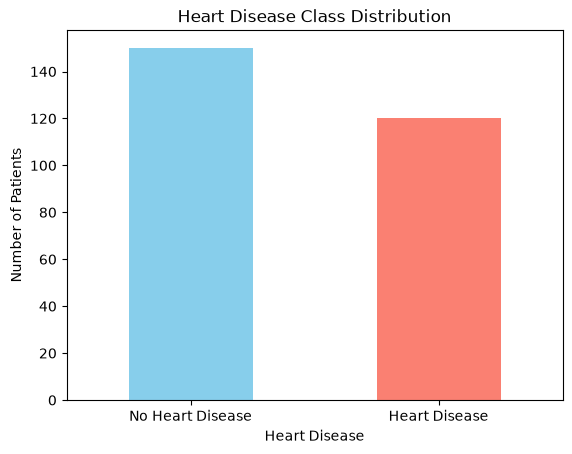

In [3]:
class_counts = df["heart disease"].value_counts().sort_index()

print(class_counts)
print(class_counts / len(df) * 100)

class_counts.plot(kind="bar", color=["skyblue", "salmon"])

plt.title("Heart Disease Class Distribution")
plt.xlabel("Heart Disease")
plt.ylabel("Number of Patients")
plt.xticks([0, 1], ["No Heart Disease", "Heart Disease"], rotation=0)
plt.show()

The dataset is reasonably balanced. Of the 270 patients, 150 (55.56%) have no heart disease and 120 (44.44%) have heart disease, so the gap between the two classes is small.

In [4]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.25,random_state=42,stratify=y)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 202
Testing records: 68


In [5]:
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(random_state=42)

In [6]:
from sklearn.model_selection import KFold, cross_val_score

kfold = KFold(n_splits=5,shuffle=True,random_state=42)

kfold_scores = cross_val_score(model,X_train,y_train,cv=kfold,scoring="accuracy")

print("K-Fold scores:", kfold_scores)
print("Mean K-Fold accuracy:", kfold_scores.mean())

K-Fold scores: [0.63414634 0.6097561  0.725      0.6        0.625     ]
Mean K-Fold accuracy: 0.6387804878048781


In [7]:
from sklearn.model_selection import StratifiedKFold

stratified_kfold = StratifiedKFold(n_splits=5,shuffle=True,random_state=42)

stratified_scores = cross_val_score(model,X_train,y_train,cv=stratified_kfold,scoring="accuracy")

print("Stratified K-Fold scores:", stratified_scores)
print("Mean Stratified K-Fold accuracy:", stratified_scores.mean())

Stratified K-Fold scores: [0.65853659 0.48780488 0.825      0.525      0.675     ]
Mean Stratified K-Fold accuracy: 0.634268292682927


In [8]:
from sklearn.model_selection import ShuffleSplit

shuffle_split = ShuffleSplit(n_splits=5,test_size=0.2,random_state=42)

shuffle_scores = cross_val_score(model,X_train,y_train,cv=shuffle_split,scoring="accuracy")

print("Shuffle Split scores:", shuffle_scores)
print("Mean Shuffle Split accuracy:", shuffle_scores.mean())

Shuffle Split scores: [0.6097561  0.63414634 0.73170732 0.56097561 0.63414634]
Mean Shuffle Split accuracy: 0.6341463414634146


In [9]:
param_grid = {
    "n_estimators": [50, 100, 200],
    "max_depth": [None, 5, 10],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4]
}

In [10]:
from sklearn.model_selection import GridSearchCV

grid_search = GridSearchCV(
    estimator=model,
    param_grid=param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Best Grid Search parameters:")
print(grid_search.best_params_)

print("Best Grid Search accuracy:")
print(grid_search.best_score_)

Best Grid Search parameters:
{'max_depth': 5, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 100}
Best Grid Search accuracy:
0.6832926829268292


In [11]:
from skopt import BayesSearchCV
from skopt.space import Integer, Categorical
bayes_search_space = {
    "n_estimators": Integer(50, 200),
    "max_depth": Categorical([None, 5, 10, 15, 20]),
    "min_samples_split": Integer(2, 10),
    "min_samples_leaf": Integer(1, 5)
}

In [12]:
bayes_search = BayesSearchCV(
    estimator=model,
    search_spaces=bayes_search_space,
    n_iter=20,
    cv=5,
    scoring="accuracy",
    random_state=42,
    n_jobs=-1
)

bayes_search.fit(X_train, y_train)

print("Best Bayesian parameters:")
print(bayes_search.best_params_)

print("Best Bayesian accuracy:")
print(bayes_search.best_score_)

Best Bayesian parameters:
OrderedDict({'max_depth': 20, 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 59})
Best Bayesian accuracy:
0.6835365853658535


In [13]:
best_bayes_model = bayes_search.best_estimator_

In [14]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

final_model = best_bayes_model

y_pred = final_model.predict(X_test)

Confusion Matrix:
[[25 13]
 [12 18]]


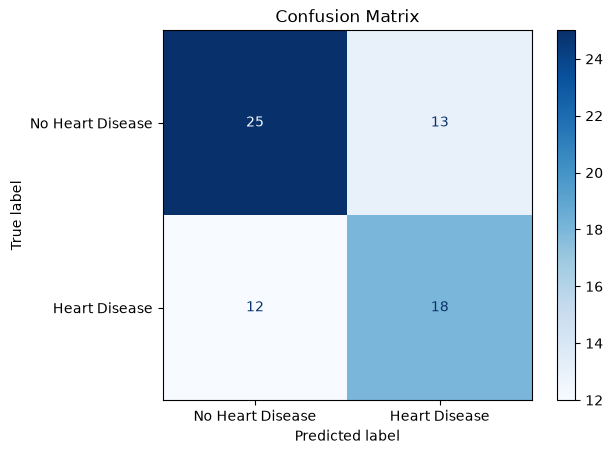

In [15]:
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Heart Disease", "Heart Disease"]
)

disp.plot(cmap="Blues")
plt.title("Confusion Matrix")
plt.show()

In [16]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)

Accuracy: 0.6323529411764706
Precision: 0.5806451612903226
Recall: 0.6
F1 Score: 0.5901639344262295


Comparing Grid Search and Bayesian Optimization

In [17]:
y_pred_grid = grid_search.best_estimator_.predict(X_test)
y_pred_bayes = bayes_search.best_estimator_.predict(X_test)

comparison = pd.DataFrame({
    "Model": ["Grid Search", "Bayesian Optimization"],
    "Accuracy": [accuracy_score(y_test, y_pred_grid), accuracy_score(y_test, y_pred_bayes)],
    "Precision": [precision_score(y_test, y_pred_grid), precision_score(y_test, y_pred_bayes)],
    "Recall": [recall_score(y_test, y_pred_grid), recall_score(y_test, y_pred_bayes)],
    "F1 Score": [f1_score(y_test, y_pred_grid), f1_score(y_test, y_pred_bayes)],
}).round(4)

comparison

,Model,Accuracy,Precision,Recall,F1 Score
0,Grid Search,0.6765,0.6111,0.7333,0.6667
1,Bayesian Optimization,0.6324,0.5806,0.6000,0.5902


A Random Forest model was trained to predict whether a patient has heart disease using age, sex, blood pressure and cholesterol. The dataset is reasonably balanced, with 55.56% of the 270 records in the no-heart-disease class and 44.44% in the heart-disease class. K-fold (0.6388), stratified k-fold (0.6343) and shuffle split (0.6341) gave similar mean accuracy. Grid search and Bayesian optimization tied in cross-validation (0.6833 and 0.6835), and the Bayesian model was kept as the final model. On the test set it scored an accuracy of 63.24%, a precision of 58.06%, a recall of 60.00% and an F1 score of 59.02%. The grid search model scored higher on the same test set (accuracy 67.65%, recall 73.33%), but that gap is only three patients out of 68, so it could come from the split and should not be treated as proof that grid search is better. All of these scores are modest, which is expected because only four features were used. The confusion matrix shows 12 false negatives out of 30 patients with heart disease, so 40% of the patients with heart disease were classified as healthy. Recall is the metric to watch here because missing a sick patient is worse than a false alarm, and more patient features would likely be needed before this model could be relied on.